# Program 38: Temperature Metrics and Consistency across Cities

**Scenario / Problem Statement**

Evaluate temperature readings across four cities, calculate mean, standard deviation, maximum, minimum, and range, and identify the most consistent city.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q38_City_Temperatures.csv
Dataset shape: (365, 5)
Weather Metric Aggregates per City:
Most consistent city (lowest standard deviation): Bangalore


,Date,Chennai_Temp_C,Delhi_Temp_C,Bangalore_Temp_C,Shimla_Temp_C
0,2025-01-01,26.1,15.3,23.1,5.7
1,2025-01-02,25.0,12.6,21.1,5.7
2,2025-01-03,27.7,14.6,20.6,7.0
3,2025-01-04,24.1,14.4,19.1,4.1
4,2025-01-05,24.3,14.0,20.0,3.6


,mean,std,max,min,range
City,,,,,
Bangalore,23.435342,2.186619,28.9,18.2,10.7
Chennai,29.495068,2.742197,35.6,24.0,11.6
Delhi,25.046575,8.257682,40.3,11.2,29.1
Shimla,14.106575,6.934597,26.6,0.9,25.7


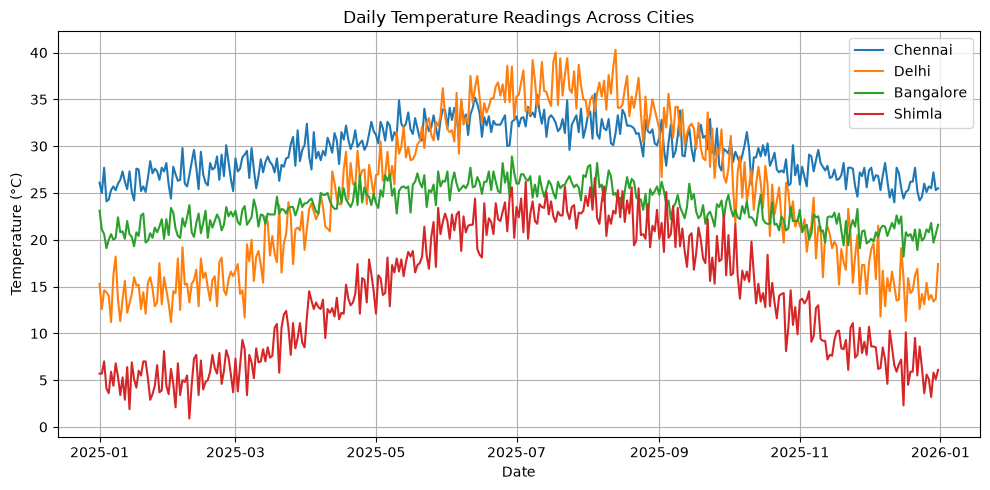

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q38_City_Temperatures.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q38_City_Temperatures.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

city_columns = ["Chennai_Temp_C", "Delhi_Temp_C", "Bangalore_Temp_C", "Shimla_Temp_C"]
for col in city_columns:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

long_df = df_raw[city_columns].melt(var_name="City", value_name="Temperature_C")
long_df["City"] = long_df["City"].str.replace("_Temp_C", "", regex=False)
stats_summary = long_df.groupby("City")["Temperature_C"].agg(["mean", "std", "max", "min"])
stats_summary["range"] = stats_summary["max"] - stats_summary["min"]

print("Weather Metric Aggregates per City:")
display(stats_summary)
print("Most consistent city (lowest standard deviation):", stats_summary["std"].idxmin())

plt.figure(figsize=(10, 5))
for col in city_columns:
    plt.plot(pd.to_datetime(df_raw["Date"]), df_raw[col], label=col.replace("_Temp_C", ""))
plt.title("Daily Temperature Readings Across Cities")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Result

The output above displays the required analysis, model results, or visualization.